Upload your Retail Sales CSV dataset


Saving dataaa.csv to dataaa.csv

Original Dataset:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

Original Shape: (541909, 8)

Cleaned Dataset:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART

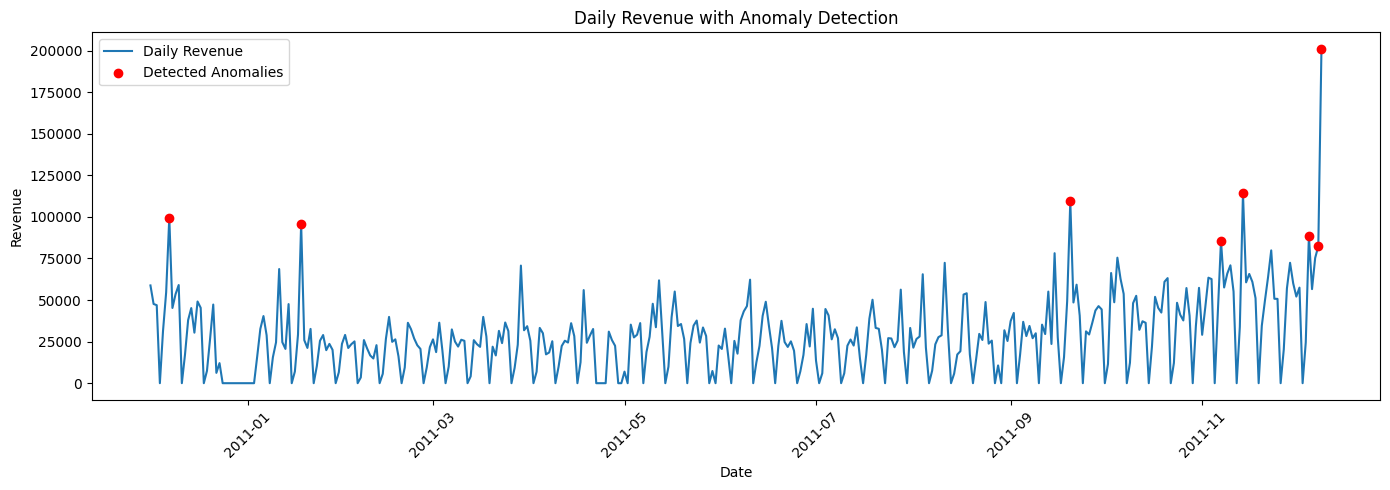

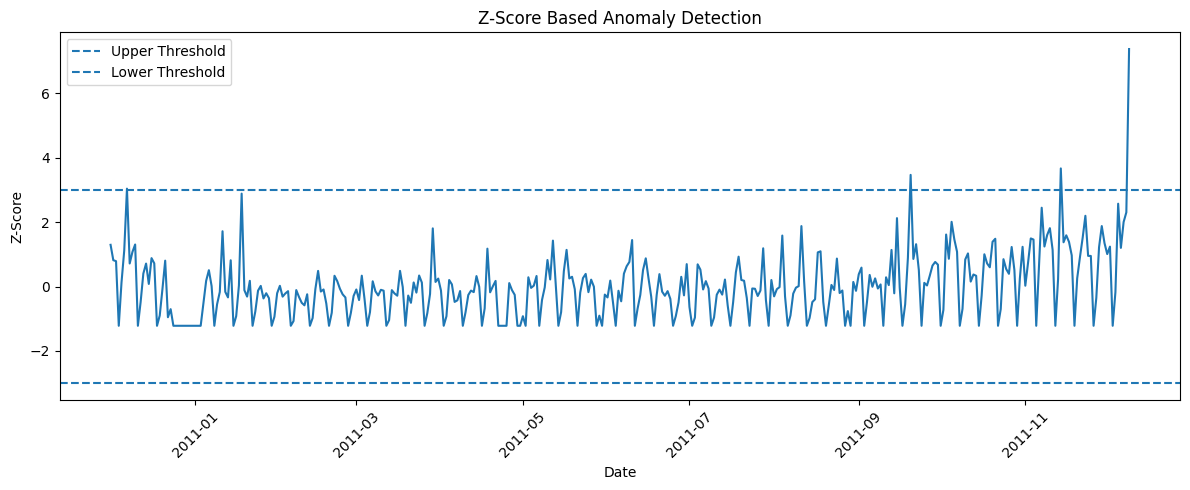

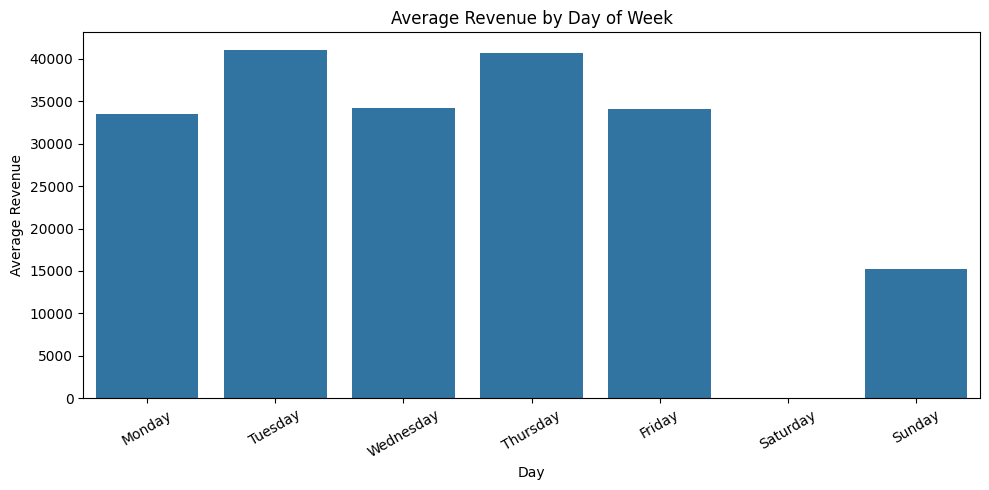

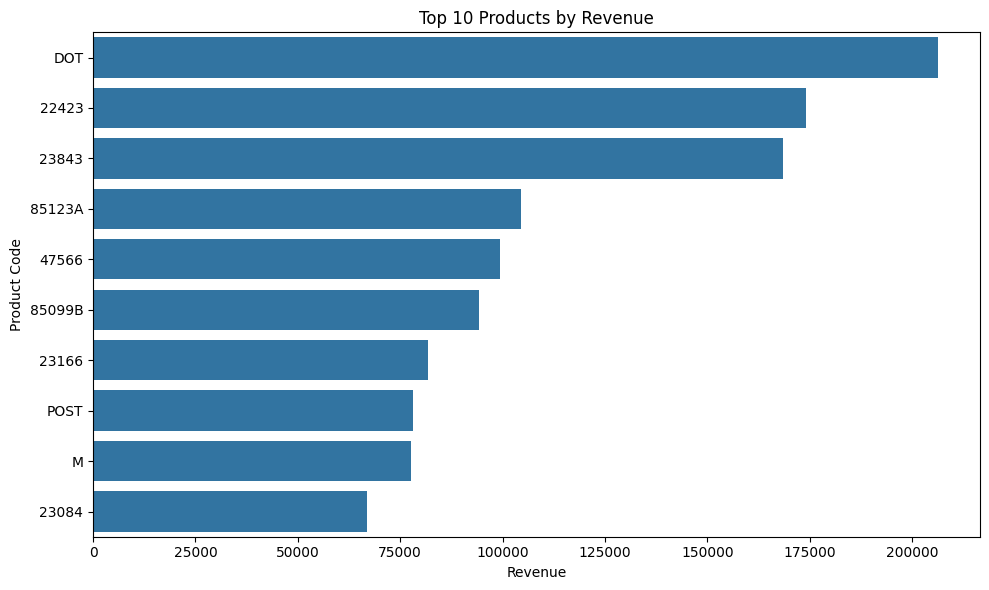


TASK 6: END-TO-END BUSINESS INSIGHTS
AND ANOMALY DETECTION SYSTEM

1. DATA CLEANING
   - Removed missing required records.
   - Removed duplicate transactions.
   - Removed cancelled invoices where available.
   - Removed invalid quantities and prices.
   - Calculated transaction revenue.

2. BUSINESS METRICS
   - Total Revenue: 10642110.80
   - Total Quantity: 5572420.00
   - Total Orders: 19960
   - Average Daily Revenue: 28454.84
   - Unique Customers: 4338

3. ANOMALY DETECTION
   - Z-score threshold: Absolute value greater than 3.
   - IQR lower bound: -29542.03
   - IQR upper bound: 81484.91
   - Total anomaly days: 8

4. HISTORICAL PATTERN ANALYSIS
   - Weekday-specific historical patterns were examined.
   - A weekday anomaly requires at least two previous
     observations and a deviation greater than three
     rolling standard deviations.

5. REVENUE INSIGHTS
   - Highest revenue date: 2011-12-09 00:00:00
   - Highest daily revenue: 200900.98
   - Lowest revenue date: 2010-

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================================
# TASK 6: END-TO-END BUSINESS INSIGHTS & ANOMALY DETECTION
# Mavrista Technologies - Data Science Internship
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
import warnings

from google.colab import files

warnings.filterwarnings("ignore")

os.makedirs("Task_6_Reports", exist_ok=True)

# ------------------------------------------------------------
# 1. UPLOAD DATASET
# ------------------------------------------------------------

print("Upload your Retail Sales CSV dataset")

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

try:
    df = pd.read_csv(file_name, encoding="ISO-8859-1")
except:
    df = pd.read_csv(file_name)

print("\nOriginal Dataset:")
print(df.head())
print("\nOriginal Shape:", df.shape)

# ------------------------------------------------------------
# 2. DATA CLEANING & COLUMN MAPPING
# ------------------------------------------------------------

df.columns = df.columns.str.strip()

# Map columns from sales_data.csv to the expected standard columns
column_mapping = {
    "Sale_Date": "InvoiceDate",
    "Quantity_Sold": "Quantity",
    "Quantity": "Quantity",
    "Unit_Price": "UnitPrice",
    "UnitPrice": "UnitPrice",
    "Product_ID": "StockCode",
    "Sales_Amount": "Revenue"
}

# Rename matching columns
rename_dict = {col: column_mapping[col] for col in df.columns if col in column_mapping}
df = df.rename(columns=rename_dict)

required_columns = [
    "InvoiceDate", "Quantity", "UnitPrice"
]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}. Available columns: {list(df.columns)}")

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

df = df.dropna(
    subset=["InvoiceDate", "Quantity", "UnitPrice"]
)

# Remove cancelled invoices if applicable
if "InvoiceNo" in df.columns:
    df["InvoiceNo"] = df["InvoiceNo"].astype(str)
    df = df[~df["InvoiceNo"].str.startswith("C")]

# Remove invalid transactions
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

df = df.drop_duplicates()

# Calculate or assign revenue
if "Revenue" not in df.columns:
    df["Revenue"] = (
        df["Quantity"] * df["UnitPrice"]
    )

print("\nCleaned Dataset:")
print(df.head())
print("\nCleaned Shape:", df.shape)
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# ------------------------------------------------------------
# 3. DAILY BUSINESS METRICS
# ------------------------------------------------------------

df["Date"] = df["InvoiceDate"].dt.normalize()

daily_metrics = df.groupby("Date").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("InvoiceNo", "nunique")
    if "InvoiceNo" in df.columns
    else ("Revenue", "count")
).reset_index()

# Count distinct customers if available
if "CustomerID" in df.columns:
    customer_daily = df.groupby("Date")[
        "CustomerID"
    ].nunique().reset_index(name="Unique_Customers")

    daily_metrics = daily_metrics.merge(
        customer_daily, on="Date", how="left"
    )

# Fill missing calendar dates with zero sales
all_dates = pd.date_range(
    daily_metrics["Date"].min(),
    daily_metrics["Date"].max(),
    freq="D"
)

daily_metrics = (
    daily_metrics.set_index("Date")
    .reindex(all_dates)
    .rename_axis("Date")
    .reset_index()
)

metric_columns = [
    "Total_Revenue",
    "Total_Quantity",
    "Total_Orders"
]

if "Unique_Customers" in daily_metrics.columns:
    metric_columns.append("Unique_Customers")

daily_metrics[metric_columns] = (
    daily_metrics[metric_columns].fillna(0)
)

print("\nDaily Business Metrics:")
print(daily_metrics.head())

# ------------------------------------------------------------
# 4. OVERALL BUSINESS SUMMARY
# ------------------------------------------------------------

total_revenue = df["Revenue"].sum()
total_quantity = df["Quantity"].sum()

if "InvoiceNo" in df.columns:
    total_orders = df["InvoiceNo"].nunique()
else:
    total_orders = len(df)

if "CustomerID" in df.columns:
    total_customers = df["CustomerID"].nunique()
else:
    total_customers = None

average_daily_revenue = daily_metrics[
    "Total_Revenue"
].mean()

business_summary = {
    "Metric": [
        "Total Revenue",
        "Total Quantity Sold",
        "Total Orders",
        "Average Daily Revenue"
    ],
    "Value": [
        round(total_revenue, 2),
        round(total_quantity, 2),
        total_orders,
        round(average_daily_revenue, 2)
    ]
}

if total_customers is not None:
    business_summary["Metric"].append(
        "Unique Customers"
    )
    business_summary["Value"].append(
        total_customers
    )

business_summary = pd.DataFrame(business_summary)

print("\nBUSINESS SUMMARY")
print(business_summary)

# ------------------------------------------------------------
# 5. Z-SCORE ANOMALY DETECTION
# ------------------------------------------------------------

# Detect unusual daily revenue using Z-score

mean_revenue = daily_metrics[
    "Total_Revenue"
].mean()

std_revenue = daily_metrics[
    "Total_Revenue"
].std()

if std_revenue > 0:
    daily_metrics["Z_Score"] = (
        daily_metrics["Total_Revenue"] - mean_revenue
    ) / std_revenue
else:
    daily_metrics["Z_Score"] = 0

# Threshold: absolute Z-score greater than 3
daily_metrics["Z_Score_Anomaly"] = (
    daily_metrics["Z_Score"].abs() > 3
)

# ------------------------------------------------------------
# 6. IQR ANOMALY DETECTION
# ------------------------------------------------------------

Q1 = daily_metrics[
    "Total_Revenue"
].quantile(0.25)

Q3 = daily_metrics[
    "Total_Revenue"
].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

daily_metrics["IQR_Anomaly"] = (
    (daily_metrics["Total_Revenue"] < lower_bound) |
    (daily_metrics["Total_Revenue"] > upper_bound)
)

# ------------------------------------------------------------
# 7. COMBINED ANOMALY DETECTION
# ------------------------------------------------------------

daily_metrics["Anomaly"] = (
    daily_metrics["Z_Score_Anomaly"] |
    daily_metrics["IQR_Anomaly"
])

daily_metrics["Anomaly_Type"] = np.select(
    [
        daily_metrics["Z_Score_Anomaly"] &
        daily_metrics["IQR_Anomaly"],

        daily_metrics["Z_Score_Anomaly"],

        daily_metrics["IQR_Anomaly"]
    ],
    [
        "Detected by Both Methods",
        "Z-Score Only",
        "IQR Only"
    ],
    default="Normal"
)

anomalies = daily_metrics[
    daily_metrics["Anomaly"]
].copy()

print("\nANOMALY DETECTION RESULTS")
print("Total Days:", len(daily_metrics))
print("Anomaly Days:", len(anomalies))
print("\nDetected Anomalies:")
print(anomalies.head(20))

# ------------------------------------------------------------
# 8. WEEKLY PATTERN ANALYSIS
# ------------------------------------------------------------

daily_metrics["Day_of_Week"] = (
    daily_metrics["Date"].dt.day_name()
)

weekly_pattern = daily_metrics.groupby(
    "Day_of_Week"
)["Total_Revenue"].mean().reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]).reset_index()

weekly_pattern.columns = [
    "Day_of_Week", "Average_Revenue"
]

# Compare each day with its weekday-specific history.
# Require at least 4 previous observations.
daily_metrics["Weekday_Mean"] = (
    daily_metrics.groupby("Day_of_Week")[
        "Total_Revenue"
    ].transform(
        lambda s: s.shift(1).rolling(
            window=4, min_periods=2
        ).mean()
    )
)

daily_metrics["Weekday_Std"] = (
    daily_metrics.groupby("Day_of_Week")[
        "Total_Revenue"
    ].transform(
        lambda s: s.shift(1).rolling(
            window=4, min_periods=2
        ).std()
    )
)

daily_metrics["Weekday_Anomaly"] = (
    (daily_metrics["Weekday_Std"] > 0) &
    (
        (daily_metrics["Total_Revenue"] -
         daily_metrics["Weekday_Mean"]).abs()
        > 3 * daily_metrics["Weekday_Std"]
    )
)

print("\nWEEKLY REVENUE PATTERN")
print(weekly_pattern)

# ------------------------------------------------------------
# 9. FINAL ANOMALY REPORT
# ------------------------------------------------------------

anomaly_report = daily_metrics[
    daily_metrics["Anomaly"] |
    daily_metrics["Weekday_Anomaly"]
].copy()

anomaly_report["Reason"] = np.select(
    [
        anomaly_report["Anomaly"] &
        anomaly_report["Weekday_Anomaly"],

        anomaly_report["Anomaly"],

        anomaly_report["Weekday_Anomaly"]
    ],
    [
        "Overall and weekday-specific unusual revenue",
        "Unusual revenue based on Z-score/IQR",
        "Unusual compared with historical weekday pattern"
    ],
    default="Normal"
)

print("\nFINAL ANOMALY REPORT")
print(anomaly_report.head(20))

# ------------------------------------------------------------
# 10. PRODUCT PERFORMANCE ANALYSIS
# ------------------------------------------------------------

if "StockCode" in df.columns:

    product_performance = df.groupby(
        "StockCode"
    ).agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    ).reset_index()

    product_performance = product_performance.sort_values(
        "Total_Revenue", ascending=False
    )

    print("\nTOP 10 PRODUCTS")
    print(product_performance.head(10))

else:
    product_performance = pd.DataFrame()

# ------------------------------------------------------------
# 11. COUNTRY PERFORMANCE
# ------------------------------------------------------------

if "Country" in df.columns:

    country_performance = df.groupby(
        "Country"
    ).agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum")
    ).reset_index().sort_values(
        "Total_Revenue", ascending=False
    )

    print("\nTOP 10 COUNTRIES")
    print(country_performance.head(10))

else:
    country_performance = pd.DataFrame()

# ------------------------------------------------------------
# 12. VISUALIZATION 1 - DAILY REVENUE
# ------------------------------------------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    daily_metrics["Date"],
    daily_metrics["Total_Revenue"],
    label="Daily Revenue"
)

plt.scatter(
    anomalies["Date"],
    anomalies["Total_Revenue"],
    label="Detected Anomalies",
    color="red",
    zorder=3
)

plt.title("Daily Revenue with Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Task_6_Reports/Daily_Revenue_Anomalies.png"
)
plt.show()

# ------------------------------------------------------------
# 13. VISUALIZATION 2 - Z-SCORE
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    daily_metrics["Date"],
    daily_metrics["Z_Score"]
)

plt.axhline(3, linestyle="--", label="Upper Threshold")
plt.axhline(-3, linestyle="--", label="Lower Threshold")

plt.title("Z-Score Based Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Z-Score")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Task_6_Reports/Z_Score_Analysis.png"
)
plt.show()

# ------------------------------------------------------------
# 14. VISUALIZATION 3 - WEEKLY PATTERN
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekly_pattern,
    x="Day_of_Week",
    y="Average_Revenue"
)

plt.title("Average Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Revenue")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "Task_6_Reports/Weekly_Revenue_Pattern.png"
)
plt.show()

# ------------------------------------------------------------
# 15. VISUALIZATION 4 - TOP PRODUCTS
# ------------------------------------------------------------

if not product_performance.empty:

    top_products = product_performance.head(10)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=top_products,
        x="Total_Revenue",
        y="StockCode"
    )

    plt.title("Top 10 Products by Revenue")
    plt.xlabel("Revenue")
    plt.ylabel("Product Code")
    plt.tight_layout()

    plt.savefig(
        "Task_6_Reports/Top_Products.png"
    )
    plt.show()

# ------------------------------------------------------------
# 16. AUTOMATED BUSINESS INSIGHTS
# ------------------------------------------------------------

highest_revenue_day = daily_metrics.loc[
    daily_metrics["Total_Revenue"].idxmax()
]

lowest_revenue_day = daily_metrics.loc[
    daily_metrics["Total_Revenue"].idxmin()
]

if not weekly_pattern.empty:
    best_weekday = weekly_pattern.loc[
        weekly_pattern["Average_Revenue"].idxmax()
    ]
else:
    best_weekday = None

if not product_performance.empty:
    best_product = product_performance.iloc[0]
else:
    best_product = None

insights = f"""
TASK 6: END-TO-END BUSINESS INSIGHTS
AND ANOMALY DETECTION SYSTEM

1. DATA CLEANING
   - Removed missing required records.
   - Removed duplicate transactions.
   - Removed cancelled invoices where available.
   - Removed invalid quantities and prices.
   - Calculated transaction revenue.

2. BUSINESS METRICS
   - Total Revenue: {total_revenue:.2f}
   - Total Quantity: {total_quantity:.2f}
   - Total Orders: {total_orders}
   - Average Daily Revenue: {average_daily_revenue:.2f}
   - Unique Customers: {total_customers}

3. ANOMALY DETECTION
   - Z-score threshold: Absolute value greater than 3.
   - IQR lower bound: {lower_bound:.2f}
   - IQR upper bound: {upper_bound:.2f}
   - Total anomaly days: {len(anomalies)}

4. HISTORICAL PATTERN ANALYSIS
   - Weekday-specific historical patterns were examined.
   - A weekday anomaly requires at least two previous
     observations and a deviation greater than three
     rolling standard deviations.

5. REVENUE INSIGHTS
   - Highest revenue date: {highest_revenue_day['Date']}
   - Highest daily revenue: {highest_revenue_day['Total_Revenue']:.2f}
   - Lowest revenue date: {lowest_revenue_day['Date']}
   - Lowest daily revenue: {lowest_revenue_day['Total_Revenue']:.2f}

6. WEEKLY INSIGHTS
   - Highest average revenue weekday:
     {best_weekday['Day_of_Week'] if best_weekday is not None else 'Not available'}

7. PRODUCT INSIGHTS
   - Top revenue product:
     {best_product['StockCode'] if best_product is not None else 'Not available'}

8. BUSINESS RECOMMENDATIONS
   - Investigate unusual revenue days before taking action.
   - Compare anomaly dates with orders and product activity.
   - Monitor revenue patterns regularly.
   - Use historical weekday patterns to reduce false alerts.
   - Review inventory and sales activity during unusual periods.

9. DATASET LIMITATIONS
   - The dataset does not provide conversion or churn data.
   - Statistical anomalies indicate unusual activity,
     not necessarily errors or fraud.
   - Holiday and promotion information is unavailable.
   - Further business investigation is required to identify
     the actual reason for each anomaly.

10. CONCLUSION
    The system combines data cleaning, business metric
    computation, historical pattern analysis and statistical
    anomaly detection to support business monitoring.
"""

print(insights)

# ------------------------------------------------------------
# 17. EXPORT REPORTS
# ------------------------------------------------------------

df.to_csv(
    "Task_6_Cleaned_Retail_Data.csv",
    index=False
)

daily_metrics.to_csv(
    "Task_6_Daily_Business_Metrics.csv",
    index=False
)

business_summary.to_csv(
    "Task_6_Business_Summary.csv",
    index=False
)

anomaly_report.to_csv(
    "Task_6_Anomaly_Report.csv",
    index=False
)

weekly_pattern.to_csv(
    "Task_6_Weekly_Pattern.csv",
    index=False
)

if not product_performance.empty:
    product_performance.to_csv(
        "Task_6_Product_Performance.csv",
        index=False
    )

if not country_performance.empty:
    country_performance.to_csv(
        "Task_6_Country_Performance.csv",
        index=False
    )

with open(
    "Task_6_Reports/Task_6_Business_Insights.txt",
    "w"
) as f:
    f.write(insights)

# ------------------------------------------------------------
# 18. CREATE ZIP FILE
# ------------------------------------------------------------

output_files = [
    "Task_6_Cleaned_Retail_Data.csv",
    "Task_6_Daily_Business_Metrics.csv",
    "Task_6_Business_Summary.csv",
    "Task_6_Anomaly_Report.csv",
    "Task_6_Weekly_Pattern.csv"
]

if not product_performance.empty:
    output_files.append(
        "Task_6_Product_Performance.csv"
    )

if not country_performance.empty:
    output_files.append(
        "Task_6_Country_Performance.csv"
    )

with zipfile.ZipFile(
    "Task_6_Analysis_Reports.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in output_files:
        zipf.write(file)

    for root, dirs, file_list in os.walk(
        "Task_6_Reports"
    ):
        for file in file_list:
            path = os.path.join(root, file)
            zipf.write(path)

print("\n====================================")
print("TASK 6 COMPLETED SUCCESSFULLY!")
print("====================================")

files.download("Task_6_Analysis_Reports.zip")
